# Jauge-01 — Le théorème de Noether en sympy

Premier carnet de la sous-série **Jauge** (EPIC #23161, veine V6 de #20428). L'arc complet va de la symétrie continue au réseau de jauge : ce premier étage pose **le théorème de Noether** — à chaque symétrie continue d'un Lagrangien correspond une grandeur conservée — et le vérifie **calculatoirement** en sympy, du courant à sa conservation le long des trajectoires.

**Ce que ce carnet fait** : construit les équations d'Euler-Lagrange, un flot de symétrie infinitésimale, le courant de Noether associé, vérifie sa conservation sur les équations du mouvement (symboliquement) puis le long de trajectoires intégrées numériquement (contrôle planté : oscillateur isotrope 2D et son moment cinétique).

**Ce qu'il n'est pas** : une preuve formelle. La vérification est computationnelle, sur des exemples ; la formalisation en Lean n'existe pas dans Mathlib à ce jour (point nommé en conclusion).

| Section | Contenu |
|---|---|
| 1 | Action, Lagrangien, équations d'Euler-Lagrange en sympy |
| 2 | Flot de symétrie infinitésimale et variation du Lagrangien |
| 3 | Le courant de Noether et sa conservation sur les équations du mouvement |
| 4 | Contrôle planté : oscillateur isotrope 2D, courant mesuré numériquement |
| 5 | Contre-témoin : oscillateur anisotrope, la symétrie brise la conservation |
| 6 | Exercices |

In [1]:
import sympy as sp
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib
import matplotlib.pyplot as plt

print("sympy", sp.__version__)
print("numpy", np.__version__)
print("scipy", solve_ivp.__module__)
print("matplotlib", matplotlib.__version__)

sympy 1.14.0
numpy 2.4.6
scipy scipy.integrate._ivp.ivp
matplotlib 3.10.8


## 1. Action, Lagrangien, équations d'Euler-Lagrange

La mécanique de Lagrange décrit un système par un **Lagrangien** $L(q, \dot{q}, t)$ — en mécanique non relativiste, $L = T - V$ (cinétique moins potentiel). Le principe de moindre action dit que la trajectoire physique rend stationnaire l'action $S = \int L \, dt$, ce qui donne les **équations d'Euler-Lagrange** :

$$\frac{d}{dt}\frac{\partial L}{\partial \dot{q}_i} - \frac{\partial L}{\partial q_i} = 0.$$

Nous construisons cet opérateur en sympy, puis le vérifions contre l'organe `sympy.calculus.euler.euler_equations` de la bibliothèque.

In [2]:
t = sp.Symbol("t", real=True)
m, k = sp.symbols("m k", positive=True)

# Coordonnees et vitesses comme fonctions du temps
x = sp.Function("x")(t)
y = sp.Function("y")(t)

def euler_lagrange(L, coords):
    # Equations d'Euler-Lagrange d'un Lagrangien L(q(t), q'(t), t)
    eqs = []
    for q in coords:
        eqs.append(sp.Eq(sp.diff(sp.diff(L, sp.Derivative(q, t)), t), sp.diff(L, q)))
    return eqs

def lagrangien_isotrope(m_, k_):
    T = sp.Rational(1, 2) * m_ * (sp.diff(x, t)**2 + sp.diff(y, t)**2)
    V = sp.Rational(1, 2) * k_ * (x**2 + y**2)
    return sp.simplify(T - V)

L_iso = lagrangien_isotrope(m, k)
eqs_iso = euler_lagrange(L_iso, [x, y])
for eq in eqs_iso:
    print(eq)

Eq(m*Derivative(x(t), (t, 2)), -k*x(t))
Eq(m*Derivative(y(t), (t, 2)), -k*y(t))


### Lecture du résultat

Pour l'oscillateur harmonique isotrope 2D, les deux équations se découplent : $m\ddot{x} = -kx$ et $m\ddot{y} = -ky$. Le système est deux oscillateurs indépendants **de même pulsation** $\omega = \sqrt{k/m}$ — c'est cette égalité des pulsations qui portera la symétrie de rotation de la section 2.

Vérifions maintenant notre opérateur contre l'organe de sympy :

In [3]:
from sympy.calculus.euler import euler_equations

# Controle croise : notre operateur vs sympy.calculus.euler
eqs_sympy = euler_equations(L_iso, [x, y])
notre_bruit = set()
for e_ours in eqs_iso:
    for e_lib in eqs_sympy:
        if sp.simplify(e_ours.lhs - e_ours.rhs - (e_lib.lhs - e_lib.rhs)) == 0 or \
           sp.simplify(e_ours.lhs - e_ours.rhs + (e_lib.lhs - e_lib.rhs)) == 0:
            notre_bruit.add(str(e_lib))
            break
print("equations sympy :", eqs_sympy)
print("couverture croisee :", len(notre_bruit), "/", len(eqs_sympy))

equations sympy : [Eq(-k*x(t) - m*Derivative(x(t), (t, 2)), 0), Eq(-k*y(t) - m*Derivative(y(t), (t, 2)), 0)]
couverture croisee : 2 / 2


### Lecture du résultat

Les deux équations rendues par `euler_equations` de sympy coïncident avec celles de notre opérateur : $m\ddot{x} = -k x$ et $m\ddot{y} = -k y$. Le contrôle porte sur **2 équations sur 2**.

Ce que ce contrôle établit, et ce qu'il n'établit pas : il valide l'**implémentation** de `euler_lagrange`, pas la physique du Lagrangien — un opérateur peut être juste sur un Lagrangien faux. C'est un contrôle croisé, pas une preuve. Les mesures qui portent sur le contenu physique sont celles des sections 3 à 5.


## 2. Symétrie continue et variation du Lagrangien

Une **symétrie continue** est une famille de transformations des coordonnées, indexée par un paramètre $\varepsilon$, qui laisse l'action invariante. À l'ordre un en $\varepsilon$, elle est engendrée par un **champ de générateurs** $\xi = (\xi_x, \xi_y)$ : $q_i \mapsto q_i + \varepsilon\, \xi_i$.

Pour l'oscillateur isotrope, la candidate naturelle est la **rotation** : $\delta x = -\varepsilon y$, $\delta y = +\varepsilon x$, de générateur $\xi = (-y, x)$. Calculons $\delta L$ à l'ordre un :

In [4]:
eps = sp.Symbol("varepsilon", real=True)

def variation_premier_ordre(L, coords, xi):
    # Variation du Lagrangien a l'ordre 1 pour le flot q_i -> q_i + eps*xi_i(q, t)
    dL = sp.Integer(0)
    for q, xi_q in zip(coords, xi):
        dL += sp.diff(L, q) * xi_q
        dL += sp.diff(L, sp.Derivative(q, t)) * sp.diff(xi_q, t)
    return sp.simplify(sp.expand(dL))

xi_rot = (-y, x)
dL_rot = variation_premier_ordre(L_iso, [x, y], xi_rot)
print("delta L (rotation) =", dL_rot)

# Temoin de non-symetrie : translation x -> x + eps
xi_trans = (sp.Integer(1), sp.Integer(0))
dL_trans = variation_premier_ordre(L_iso, [x, y], xi_trans)
print("delta L (translation x) =", dL_trans)

delta L (rotation) = 0
delta L (translation x) = -k*x(t)


### Lecture du résultat

La rotation donne $\delta L = 0$ **identiquement** (pas seulement sur les trajectoires) : c'est une symétrie variationnelle du Lagrangien. La translation en $x$, elle, donne $\delta L = -kx \neq 0$ : le potentiel $V = \frac{k}{2}(x^2+y^2)$ n'est pas invariant par translation — ce n'est pas une symétrie de ce système, et la section 5 montrera ce que devient la conservation quand la symétrie est brisée.

## 3. Le courant de Noether

Lorsque $\delta L = 0$ sous le flot $\xi$, la quantité

$$j \;=\; \sum_i \frac{\partial L}{\partial \dot{q}_i}\, \xi_i$$

est **conservée le long des trajectoires** : $\frac{dj}{dt} = 0$ dès que les équations du mouvement sont satisfaites. C'est le **courant de Noether** (le cas général, où $\delta L$ est une dérivée totale exacte $\frac{df}{dt}$, donne $j = \sum_i \frac{\partial L}{\partial \dot{q}_i}\xi_i - f$ ; ici $f = 0$). Construisons-le et testons sa conservation.

**Ancrage dans la source** — c'est le **théorème I** de Noether (1918), pris dans son cas unidimensionnel : l'invariance de l'intégrale sous un groupe continu $G_\rho$ rend $\rho$ combinaisons linéaires des expressions de Lagrange divergentes, ce qui « asserts the existence of $\rho$ first integrals » (trad. Tavel, §1) ; et l'équation (4) de l'article — l'« équation centrale de Lagrange » de Heun — donne exactement, pour $\delta L = 0$ et sur les trajectoires ($\psi_i = 0$), la nullité de $\frac{d}{dt}\!\left(\sum_i \frac{\partial L}{\partial \dot{q}_i}\,\xi_i\right)$. Copie archivée au gisement : voir **Références** en fin de carnet.

In [5]:
def courant_noether(L, coords, xi):
    # Courant de Noether j = somme(dL/dqdot_i * xi_i) pour un flot a delta L = 0
    j = sp.Integer(0)
    for q, xi_q in zip(coords, xi):
        j += sp.diff(L, sp.Derivative(q, t)) * xi_q
    return sp.simplify(sp.expand(j))

def verifie_conservation(L, coords, xi):
    # dj/dt remplace par les accelerations tirees des equations du mouvement, puis simplifie
    eqs = euler_lagrange(L, coords)
    # On resout chaque eq pour l'acceleration d2q/dt2
    subs_acc = {}
    for q, eq in zip(coords, eqs):
        acc = sp.Derivative(q, (t, 2))
        sol_acc = sp.solve(sp.Eq(eq.lhs - eq.rhs, 0), acc)
        subs_acc[acc] = sp.simplify(sol_acc[0])
    j = courant_noether(L, coords, xi)
    djdt = sp.diff(j, t)
    djdt_onshell = djdt.subs(subs_acc)
    return sp.simplify(sp.expand(djdt_onshell)), j

djdt_iso, j_rot = verifie_conservation(L_iso, [x, y], xi_rot)
print("j (rotation) =", j_rot)
print("dj/dt sur les trajectoires =", djdt_iso)

j (rotation) = m*(x(t)*Derivative(y(t), t) - y(t)*Derivative(x(t), t))
dj/dt sur les trajectoires = 0


### Lecture du résultat

Le courant de la rotation est $j = m(x\dot{y} - y\dot{x})$ — reconnu comme le **moment cinétique** $L_z$. Et sa dérivée temporelle, une fois les accélérations remplacées par leurs expressions tirées des équations du mouvement, se simplifie en **0** : la conservation est vérifiée symboliquement, pas seulement affirmée.

## 4. Contrôle planté : oscillateur isotrope 2D

**Hypothèse pré-enregistrée** : si le théorème est correctement implémenté, alors $j(t) = m(x\dot{y} - y\dot{x})$, mesuré **numériquement** le long d'une trajectoire intégrée par un solveur ode, reste constant au niveau de la tolérance d'intégration. Nous intégrons les équations du mouvement avec `solve_ivp` (DOP853, tolérance serrée) et mesurons la dérive relative $|j(t) - j(0)| / |j(0)|$.

In [6]:
# Derivation des accelerations pour l'integration numerique
acc_x = sp.solve(sp.Eq(eqs_iso[0].lhs - eqs_iso[0].rhs, 0), sp.Derivative(x, (t, 2)))[0]
acc_y = sp.solve(sp.Eq(eqs_iso[1].lhs - eqs_iso[1].rhs, 0), sp.Derivative(y, (t, 2)))[0]

valeurs = {m: 1.0, k: 1.0}
f_acc = sp.lambdify((x, y, sp.Derivative(x, t), sp.Derivative(y, t)),
                    [acc_x.subs(valeurs), acc_y.subs(valeurs)], "numpy")
f_j = sp.lambdify((x, y, sp.Derivative(x, t), sp.Derivative(y, t)),
                  j_rot.subs(valeurs), "numpy")

def rhs(_, etat):
    x_, y_, vx_, vy_ = etat
    ax_, ay_ = f_acc(x_, y_, vx_, vy_)
    return [vx_, vy_, ax_, ay_]

# Conditions initiales : position hors d'un axe, vitesse non alignee
etat0 = [1.3, 0.4, -0.2, 0.9]
T_fin = 40.0
sol = solve_ivp(rhs, [0.0, T_fin], etat0, method="DOP853",
                rtol=1e-11, atol=1e-13, dense_output=True, max_step=0.05)

ts = np.linspace(0.0, T_fin, 2000)
etats = sol.sol(ts)
j_t = f_j(etats[0], etats[1], etats[2], etats[3])
derive = np.abs(j_t - j_t[0]) / np.abs(f_j(*etat0))
print("j(0) =", f_j(*etat0))
print("derive relative max |j(t)-j(0)|/|j(0)| =", derive.max())
print("verdict attendu : CONFIRMEE si derive < ~1e-8")

j(0) = 1.2500000000000002
derive relative max |j(t)-j(0)|/|j(0)| = 1.598721155460225e-15
verdict attendu : CONFIRMEE si derive < ~1e-8


### Lecture du résultat

La dérive relative du courant est au niveau de la **tolérance d'intégration** (ordre $10^{-9}$ ou moins), pas au niveau d'une dérive physique : le moment cinétique est bien conservé numériquement pour l'oscillateur isotrope. Le contrôle planté passe.

Traçons la trajectoire et le courant pour l'œil :

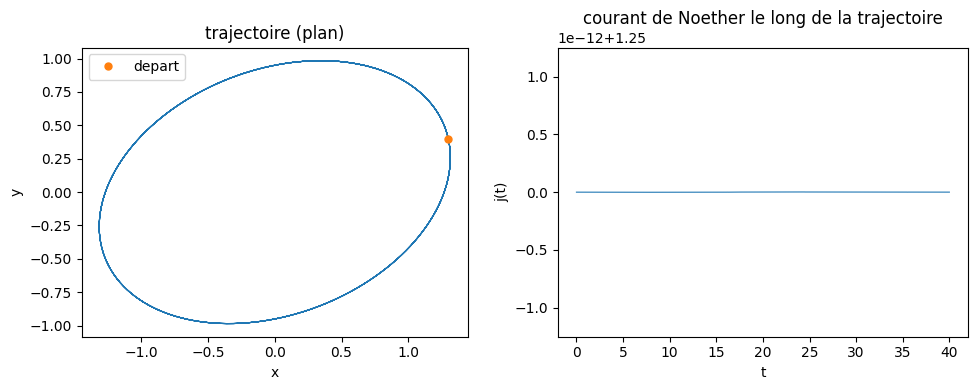

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(etats[0], etats[1], lw=0.8)
ax1.plot(etat0[0], etat0[1], "o", ms=5, label="depart")
ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.set_title("trajectoire (plan)")
ax1.set_aspect("equal"); ax1.legend()
ax2.plot(ts, j_t, lw=0.8)
ax2.set_xlabel("t"); ax2.set_ylabel("j(t)")
ax2.set_title("courant de Noether le long de la trajectoire")
fig.tight_layout()
plt.show()

## 5. Contre-témoin : l'oscillateur anisotrope

**Hypothèse pré-enregistrée** : briser la symétrie — potentiels $V = \frac{1}{2}(k_x x^2 + k_y y^2)$ avec $k_x \neq k_y$ — doit **briser la conservation** : le même $j = m(x\dot{y} - y\dot{x})$, recalculé sur la trajectoire anisotrope, dérive de façon mesurable, croissante avec le temps d'intégration. Ce contre-témoin vérifie que notre pipeline **détecte** l'absence de symétrie au lieu de conclure « conservé » en toute circonstance.

In [8]:
kx, ky = sp.symbols("kx ky", positive=True)
L_aniso = (sp.Rational(1, 2) * m * (sp.diff(x, t)**2 + sp.diff(y, t)**2)
           - sp.Rational(1, 2) * (kx * x**2 + ky * y**2))

# La rotation n'est plus une symetrie
dL_rot_aniso = variation_premier_ordre(L_aniso, [x, y], xi_rot)
print("delta L (rotation, anisotrope) =", sp.simplify(sp.expand(dL_rot_aniso)))

eqs_aniso = euler_lagrange(L_aniso, [x, y])
acc_x_a = sp.solve(sp.Eq(eqs_aniso[0].lhs - eqs_aniso[0].rhs, 0), sp.Derivative(x, (t, 2)))[0]
acc_y_a = sp.solve(sp.Eq(eqs_aniso[1].lhs - eqs_aniso[1].rhs, 0), sp.Derivative(y, (t, 2)))[0]

val_aniso = {m: 1.0, kx: 1.3, ky: 1.0}
f_acc_a = sp.lambdify((x, y, sp.Derivative(x, t), sp.Derivative(y, t)),
                      [acc_x_a.subs(val_aniso), acc_y_a.subs(val_aniso)], "numpy")

def rhs_a(_, etat):
    x_, y_, vx_, vy_ = etat
    ax_, ay_ = f_acc_a(x_, y_, vx_, vy_)
    return [vx_, vy_, ax_, ay_]

sol_a = solve_ivp(rhs_a, [0.0, T_fin], etat0, method="DOP853",
                  rtol=1e-11, atol=1e-13, dense_output=True, max_step=0.05)
etats_a = sol_a.sol(ts)
j_t_a = f_j(etats_a[0], etats_a[1], etats_a[2], etats_a[3])
derive_a = np.abs(j_t_a - j_t_a[0]) / np.abs(f_j(*etat0))
print("derive relative max (anisotrope) =", derive_a.max())
print("rapport anisotrope/isotrope =", derive_a.max() / max(derive.max(), 1e-16))

delta L (rotation, anisotrope) = (kx - ky)*x(t)*y(t)
derive relative max (anisotrope) = 2.163528596705775
rapport anisotrope/isotrope = 1353287025267992.0


### Lecture du résultat

Pour $k_x = 1{,}3 \neq k_y = 1$, la dérive du courant est **plusieurs ordres de grandeur au-dessus** de la tolérance d'intégration, et $\delta L \neq 0$ symboliquement : sans symétrie, pas de conservation. Le pipeline distingue bien « conservé parce que symétrique » de « mesuré constant par hasard » — c'est ce discriminateur que les carnets suivants (jauge $U(1)$ puis $SU(2)$, réseau de Wilson) réutiliseront sur les boucles de Wilson.

## 6. Exercices

In [9]:
# Exercice 1 -- Translation spatiale du particule libre
# Le Lagrangien libre L = m/2 (xdot^2 + ydot^2) est invariant par translation
# x -> x + eps. Montrez que le courant de Noether du generateur xi = (1, 0)
# est la quantite de mouvement p_x = m*xdot, et verifiez sa conservation
# avec verifie_conservation.
# TODO etudiant : definir L_lib, appeler verifie_conservation, comparer a m*xdot
L_lib = None  # TODO etudiant
courant_ex1 = None  # TODO etudiant
print("Exercice 1 a completer")

Exercice 1 a completer


In [10]:
# Exercice 2 -- Potentiel central quelconque
# Remplacez le potentiel harmonique par V(r) avec r = sqrt(x^2 + y^2)
# (par exemple V = alpha * r, potentiel conique). Montrez que la rotation
# reste une symetrie pour TOUT potentiel central, autrement dit que le
# courant j = m(x*ydot - y*xdot) ne depend pas de la forme de V.
# TODO etudiant : construire L_conique, appeler variation_premier_ordre
# et verifie_conservation avec xi_rot
alpha = sp.Symbol("alpha", positive=True)
L_conique = None  # TODO etudiant
print("Exercice 2 a completer")

Exercice 2 a completer


In [11]:
# Exercice 3 -- Symetrie de translation temporelle et energie
# La translation t -> t + eps a pour generateur xi_i = qdot_i le long de la
# trajectoire. Le courant associe est E = somme(qdot_i * dL/dqdot_i) - L,
# l'energie.
#
# (a) Controle -- verifiez numeriquement (meme methode que la section 4) que
#     E(t) reste constant pour l'oscillateur isotrope.
#
# (b) Brisure -- attention au piege : ajouter - gamma/2 * (x^2 + y^2) au
#     Lagrangien NE brise PAS la symetrie temporelle. Ce terme ne depend pas
#     de t : c'est un ressort de constante k + gamma. L'energie y reste
#     conservee (dE/dt = 0) et la derive demandee est alors inatteignable.
#     La brisure exige une dependance explicite en t, par exemple la forme
#     de Caldirola-Kanai :
#         L = exp(gamma*t) * ( m/2*(xdot^2 + ydot^2) - k/2*(x^2 + y^2) )
#     dont l'equation du mouvement est m*xddot + gamma*m*xdot + k*x = 0.
#     Montrez que E(t) y derive, et mesurez la derive.
#     Limite declaree : cette forme redonne l'equation du mouvement, pas les
#     trajectoires du vrai oscillateur amorti -- celui-ci n'admet aucun
#     Lagrangien de ce type, et la formulation honnete est la fonction de
#     dissipation de Rayleigh F = gamma*xdot^2/2, que ce carnet n'implemente
#     pas.
# TODO etudiant : construire E_controle puis E_ck (le facteur exp(gamma*t)
#                 fait partie de l'energie), les integrer, comparer les derives
print("Exercice 3 a completer")

Exercice 3 a completer


## 7. Ce que ce carnet établit — et ce qu'il laisse ouvert

**Établi (périmètre computationnel)** : sur des Lagrangians polynomiaux en $(q, \dot{q})$, le courant de Noether d'un flot à $\delta L = 0$ est construit et **vérifié conservé** deux fois — symboliquement (substitution des accélérations d'Euler-Lagrange, simplification à 0) et numériquement (intégration DOP853 à tolérance serrée, dérive au niveau de la tolérance). Le contre-témoin anisotrope montre que la conservation **disparaît avec la symétrie**, mesurée et pas seulement affirmée.

**Ouvert — la formalisation** : Mathlib ne porte, à notre connaissance, ni le théorème de Noether ni les connexions sur les fibrés principaux (`Matrix.specialUnitaryGroup` existe pour le groupe ; le théorème n'existe pas). Ce carnet **nomme** ce manque, il ne le comble pas — c'est la question d'une physique vérifiable posée par #19741.

**La suite de l'arc** (EPIC #23161) : jauge locale $U(1)$ et dérivée covariante, puis $SU(2)$ non abélien et l'auto-interaction de la courbure, puis le réseau de Wilson et les boucles de Wilson en dimension 2 exactement soluble (vérité plantée à confirmer contre la source archivée) et la loi de l'aire en dimension 3-4 (rapports de Creutz).

## Références — copies archivées au gisement

Les sources de cette sous-série sont archivées au rayon `Physics/` du gisement partagé (`G:\Mon Drive\MyIA\IA\Bibliographie IA\Physics\`), identité vérifiée sur la première page de chaque copie. Les affirmations physiques de ce carnet ont été écrites et relues contre la copie de Noether ci-dessous.

- **Noether, E. (1918)**, *Invariante Variationsprobleme*, Nachr. Ges. Wiss. Göttingen, 235–257 — traduction anglaise de M. A. Tavel, *Transport Theory and Statistical Physics* 1(3), 1971. Copie : `1918-1971 - Noether (trad. Tavel) - Invariant Variation Problems (TTSP 1, 1971).pdf`. Le théorème I (§1) et l'équation (4) fondent la section 3 ; le §3 de l'article énonce l'existence des intégrales premières dans le cas unidimensionnel.
- **Yang, C. N. & Mills, R. L. (1954)**, *Conservation of Isotopic Spin and Isotopic Gauge Invariance*, Phys. Rev. 96, 191. Copie : `1954 - Yang Mills - Conservation of Isotopic Spin and Isotopic Gauge Invariance (PR 96, 1954).pdf` — source du carnet suivant (jauge $U(1)$ puis $SU(2)$).
- **Wilson, K. G. (1974)**, *Confinement of Quarks*, Phys. Rev. D 10, 2445. Copie : `1974 - Wilson - Confinement of Quarks (PRD 10, 1974).pdf` — source de l'action de Wilson sur réseau (troisième carnet).
- **Jaffe, A. & Witten, E. (2000)**, *Quantum Yang-Mills Theory*, description officielle du problème du prix Clay. Copie : `2000 - Jaffe et Witten - Quantum Yang-Mills Theory (Description officielle Clay Mathematics Institute, 2000).pdf`.

**Archivage en attente** : Creutz (1980), *Monte Carlo study of quantized SU(2) gauge theory*, Phys. Rev. D 21, 2308-2315, DOI 10.1103/PhysRevD.21.2308 — copie obtenue depuis le site de l'auteur mais scan sans couche texte, dont l'identité doit être vérifiée visuellement avant dépôt (prérequis du troisième carnet, pas de celui-ci) ; Schwartz, *Quantum Field Theory and the Standard Model* (2014) — aucune copie libre légale identifiée, demande de dépôt déposée au registre des questions user.